# Model Comparison — TFLite ECG Classifiers

Compare the 3 trained architectures on the **test set (Fold 10)**:

| Model | TFLite File |
|-------|-------------|
| **ResNet1D** | `models/ecg_model_fp16.tflite` |
| **InceptionTime** | `models/inception/inception_fp16.tflite` |
| **ECG-Transformer** | `models/transformer/transformer_fp16.tflite` |

Metrics: per-class & macro AUC, F1, model size, inference latency.

## 1. Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import numpy as np, os, json, time
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import (
    roc_auc_score, f1_score, classification_report,
    roc_curve, confusion_matrix
)
import warnings; warnings.filterwarnings('ignore')

print(f"TF {tf.__version__}")
np.random.seed(42)

TF 2.19.0


## 2. Load Test Data

In [3]:
drive_path = 'drive/MyDrive/ECG'
data_dir = os.path.join(drive_path, 'preprocessed')

with open(os.path.join(data_dir, 'metadata.json'), 'r') as f:
    meta = json.load(f)

SUPERCLASSES = meta['superclasses']

X_test = np.load(os.path.join(data_dir, 'X_test.npy'))
Y_test = np.load(os.path.join(data_dir, 'Y_test.npy'))
F_test = np.load(os.path.join(data_dir, 'F_test.npy'))

# Apply same FFT bandpass as training notebooks
def fft_bandpass_filter(X, fs=100, low=0.5, high=40.0):
    N, T, L = X.shape
    freqs = np.fft.rfftfreq(T, d=1.0/fs)
    mask = np.ones(len(freqs), dtype=np.float32)
    mask[freqs < low] = 0.0; mask[freqs > high] = 0.0
    tw = 0.5
    for i, f_val in enumerate(freqs):
        if low <= f_val < low + tw: mask[i] = (f_val - low) / tw
        elif high - tw < f_val <= high: mask[i] = (high - f_val) / tw
    Xf = np.zeros_like(X)
    for lead in range(L):
        fd = np.fft.rfft(X[:, :, lead], axis=1)
        fd *= mask[np.newaxis, :]
        Xf[:, :, lead] = np.fft.irfft(fd, n=T, axis=1)
    return Xf.astype(np.float32)

X_test = fft_bandpass_filter(X_test)
print(f"Test set: {X_test.shape[0]} samples | Signal: {X_test.shape[1:]} | Features: {F_test.shape[1]}")
print(f"Superclasses: {SUPERCLASSES}")

Test set: 2198 samples | Signal: (1000, 12) | Features: 531
Superclasses: ['NORM', 'MI', 'STTC', 'CD', 'HYP']


## 3. TFLite Inference Engine

In [4]:
def load_and_run_tflite(tflite_path, X_sig, X_feat):
    """
    Run TFLite inference on full test set.
    Returns: predictions array, model size (MB), mean latency (ms/sample)
    """
    interp = tf.lite.Interpreter(model_path=tflite_path)
    interp.allocate_tensors()
    inp_details = interp.get_input_details()
    out_details = interp.get_output_details()

    # Map inputs by name
    sig_idx, feat_idx = None, None
    for d in inp_details:
        name_lower = d['name'].lower()
        if 'signal' in name_lower:
            sig_idx = d['index']
        elif 'feature' in name_lower:
            feat_idx = d['index']
    # Fallback: first input = signal, second = feature
    if sig_idx is None:
        sig_idx = inp_details[0]['index']
        feat_idx = inp_details[1]['index'] if len(inp_details) > 1 else None

    preds = []
    t_start = time.perf_counter()
    for i in range(len(X_sig)):
        interp.set_tensor(sig_idx, X_sig[i:i+1].astype(np.float32))
        if feat_idx is not None:
            interp.set_tensor(feat_idx, X_feat[i:i+1].astype(np.float32))
        interp.invoke()
        preds.append(interp.get_tensor(out_details[0]['index'])[0])
    t_elapsed = time.perf_counter() - t_start

    size_mb = os.path.getsize(tflite_path) / 1e6
    latency_ms = (t_elapsed / len(X_sig)) * 1000

    return np.array(preds), size_mb, latency_ms

print('\u2713 Inference engine ready')

✓ Inference engine ready


## 4. Run All Models

In [5]:
MODELS = {
    'ResNet1D': os.path.join(drive_path, 'models', 'ecg_model_fp16.tflite'),
    'InceptionTime': os.path.join(drive_path, 'models', 'inception', 'inception_fp16.tflite'),
    'Transformer': os.path.join(drive_path, 'models', 'transformer', 'transformer_fp16.tflite'),
}

results = {}  # model_name -> {preds, size_mb, latency_ms, auc_per_class, f1_per_class, macro_auc, macro_f1}

for name, path in MODELS.items():
    print(f'\n{"="*60}')
    print(f'  {name}')
    print(f'{"="*60}')

    if not os.path.exists(path):
        print(f'  \u26a0 File not found: {path} — skipping')
        continue

    preds, size_mb, latency_ms = load_and_run_tflite(path, X_test, F_test)
    preds_bin = (preds >= 0.5).astype(int)

    auc_per_class = {}
    for i, sc in enumerate(SUPERCLASSES):
        try:
            auc_per_class[sc] = roc_auc_score(Y_test[:, i], preds[:, i])
        except ValueError:
            auc_per_class[sc] = float('nan')

    macro_auc = np.nanmean(list(auc_per_class.values()))
    f1_per_class = f1_score(Y_test, preds_bin, average=None, zero_division=0)
    macro_f1 = f1_score(Y_test, preds_bin, average='macro', zero_division=0)

    results[name] = {
        'preds': preds, 'preds_bin': preds_bin,
        'size_mb': size_mb, 'latency_ms': latency_ms,
        'auc_per_class': auc_per_class, 'f1_per_class': f1_per_class,
        'macro_auc': macro_auc, 'macro_f1': macro_f1,
    }

    print(f'  Size: {size_mb:.2f} MB | Latency: {latency_ms:.2f} ms/sample')
    print(f'  Macro AUC: {macro_auc:.4f} | Macro F1: {macro_f1:.4f}')
    for sc in SUPERCLASSES:
        print(f'    {sc:>5}: AUC={auc_per_class[sc]:.4f}  F1={f1_per_class[SUPERCLASSES.index(sc)]:.4f}')

print(f'\n\u2713 All models evaluated ({len(results)}/{len(MODELS)})')


  ResNet1D
  Size: 9.83 MB | Latency: 19.47 ms/sample
  Macro AUC: 0.9140 | Macro F1: 0.7145
     NORM: AUC=0.9432  F1=0.8532
       MI: AUC=0.9076  F1=0.7127
     STTC: AUC=0.9276  F1=0.7353
       CD: AUC=0.8987  F1=0.7007
      HYP: AUC=0.8929  F1=0.5708

  InceptionTime
  Size: 7.43 MB | Latency: 33.91 ms/sample
  Macro AUC: 0.9210 | Macro F1: 0.7242
     NORM: AUC=0.9454  F1=0.8443
       MI: AUC=0.9096  F1=0.7112
     STTC: AUC=0.9299  F1=0.7526
       CD: AUC=0.9181  F1=0.7169
      HYP: AUC=0.9018  F1=0.5958

  Transformer
  Size: 1.54 MB | Latency: 0.89 ms/sample
  Macro AUC: 0.9018 | Macro F1: 0.6858
     NORM: AUC=0.9344  F1=0.8309
       MI: AUC=0.8743  F1=0.6699
     STTC: AUC=0.9265  F1=0.7329
       CD: AUC=0.8914  F1=0.6900
      HYP: AUC=0.8823  F1=0.5051

✓ All models evaluated (3/3)


## 5. Summary Table

In [6]:
# ── Formatted comparison table ──
header = f"{'Model':<16} {'Macro AUC':>10} {'Macro F1':>10} {'Size (MB)':>10} {'Latency':>10}"
print('=' * len(header))
print(header)
print('=' * len(header))

# Sort by macro AUC descending
ranked = sorted(results.items(), key=lambda x: x[1]['macro_auc'], reverse=True)

for name, r in ranked:
    marker = ' \u2b50' if name == ranked[0][0] else ''
    print(f"{name:<16} {r['macro_auc']:>10.4f} {r['macro_f1']:>10.4f} "
          f"{r['size_mb']:>9.2f}M {r['latency_ms']:>8.2f}ms{marker}")

print('=' * len(header))

# Per-class breakdown
print(f"\n{'':>16}", end='')
for sc in SUPERCLASSES:
    print(f"  {sc:>10}", end='')
print()

for name, r in ranked:
    print(f"{name + ' AUC':<16}", end='')
    for sc in SUPERCLASSES:
        print(f"  {r['auc_per_class'][sc]:>10.4f}", end='')
    print()
    print(f"{name + ' F1':<16}", end='')
    for i, sc in enumerate(SUPERCLASSES):
        print(f"  {r['f1_per_class'][i]:>10.4f}", end='')
    print('\n')

Model             Macro AUC   Macro F1  Size (MB)    Latency
InceptionTime        0.9210     0.7242      7.43M    33.91ms ⭐
ResNet1D             0.9140     0.7145      9.83M    19.47ms
Transformer          0.9018     0.6858      1.54M     0.89ms

                        NORM          MI        STTC          CD         HYP
InceptionTime AUC      0.9454      0.9096      0.9299      0.9181      0.9018
InceptionTime F1      0.8443      0.7112      0.7526      0.7169      0.5958

ResNet1D AUC          0.9432      0.9076      0.9276      0.8987      0.8929
ResNet1D F1           0.8532      0.7127      0.7353      0.7007      0.5708

Transformer AUC       0.9344      0.8743      0.9265      0.8914      0.8823
Transformer F1        0.8309      0.6699      0.7329      0.6900      0.5051



## 6. Visual Comparison

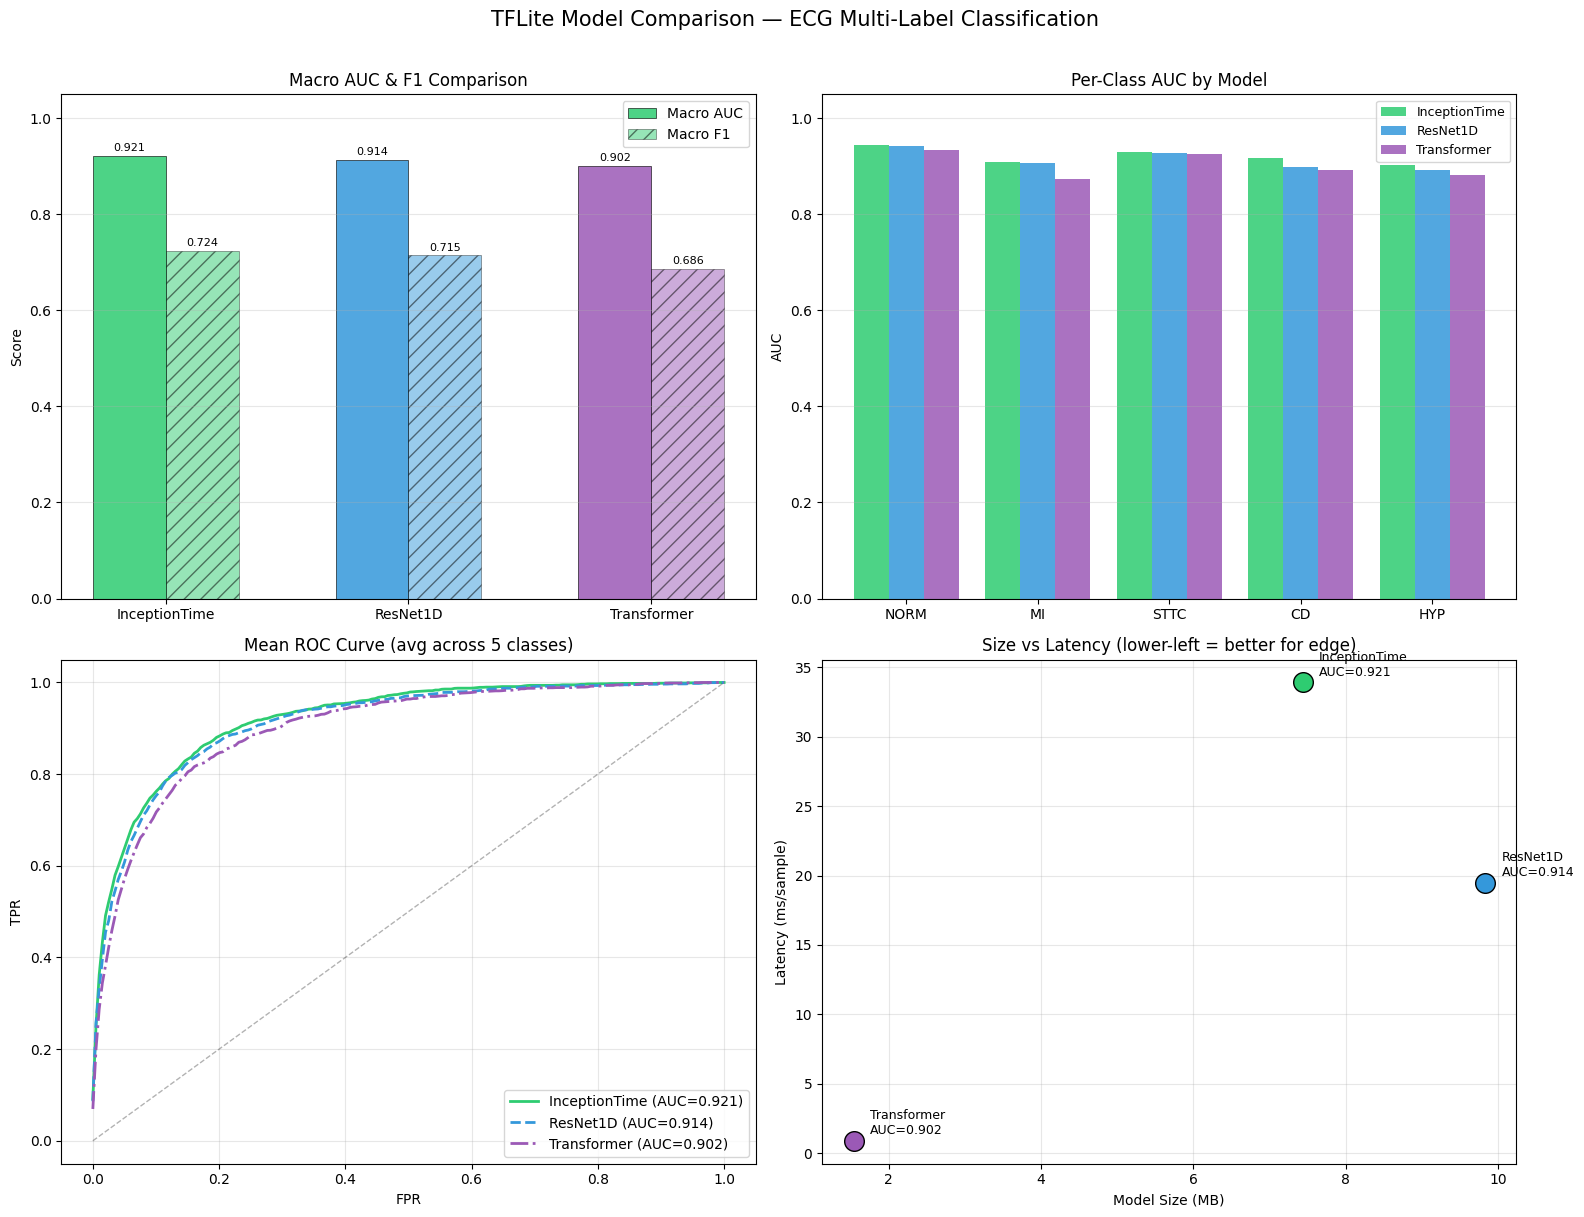

In [7]:
model_names = [n for n, _ in ranked]
model_colors = {'ResNet1D': '#3498db', 'InceptionTime': '#2ecc71', 'Transformer': '#9b59b6'}
colors = [model_colors.get(n, '#95a5a6') for n in model_names]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# ── 1. Macro AUC & F1 bar chart ──
ax = axes[0, 0]
x = np.arange(len(model_names))
aucs = [results[n]['macro_auc'] for n in model_names]
f1s  = [results[n]['macro_f1'] for n in model_names]
ax.bar(x - 0.15, aucs, 0.3, label='Macro AUC', color=colors, alpha=0.85, edgecolor='black', linewidth=0.5)
ax.bar(x + 0.15, f1s,  0.3, label='Macro F1', color=colors, alpha=0.5, edgecolor='black', linewidth=0.5, hatch='//')
ax.set_xticks(x); ax.set_xticklabels(model_names)
ax.set_ylim(0, 1.05); ax.set_ylabel('Score')
ax.set_title('Macro AUC & F1 Comparison')
ax.legend(); ax.grid(axis='y', alpha=0.3)
for i, (a, f) in enumerate(zip(aucs, f1s)):
    ax.text(i - 0.15, a + 0.01, f'{a:.3f}', ha='center', fontsize=8)
    ax.text(i + 0.15, f + 0.01, f'{f:.3f}', ha='center', fontsize=8)

# ── 2. Per-class AUC grouped bar ──
ax = axes[0, 1]
n_models = len(model_names)
n_classes = len(SUPERCLASSES)
width = 0.8 / n_models
for j, name in enumerate(model_names):
    r = results[name]
    vals = [r['auc_per_class'][sc] for sc in SUPERCLASSES]
    positions = np.arange(n_classes) + j * width - (n_models - 1) * width / 2
    ax.bar(positions, vals, width, label=name, color=model_colors.get(name, '#95a5a6'), alpha=0.85)
ax.set_xticks(np.arange(n_classes)); ax.set_xticklabels(SUPERCLASSES)
ax.set_ylim(0, 1.05); ax.set_ylabel('AUC')
ax.set_title('Per-Class AUC by Model')
ax.legend(fontsize=9); ax.grid(axis='y', alpha=0.3)

# ── 3. ROC curves (one per model, all classes) ──
ax = axes[1, 0]
line_styles = ['-', '--', '-.']
for j, name in enumerate(model_names):
    preds = results[name]['preds']
    macro_auc = results[name]['macro_auc']
    # Plot mean ROC (micro-average)
    fpr_all, tpr_all = [], []
    for i in range(n_classes):
        fpr, tpr, _ = roc_curve(Y_test[:, i], preds[:, i])
        fpr_all.append(fpr); tpr_all.append(tpr)
    # Interpolate to common FPR grid
    mean_fpr = np.linspace(0, 1, 200)
    mean_tpr = np.zeros_like(mean_fpr)
    for fpr, tpr in zip(fpr_all, tpr_all):
        mean_tpr += np.interp(mean_fpr, fpr, tpr)
    mean_tpr /= n_classes
    ax.plot(mean_fpr, mean_tpr, linestyle=line_styles[j % 3],
            color=model_colors.get(name, '#95a5a6'), linewidth=2,
            label=f'{name} (AUC={macro_auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.3)
ax.set(xlabel='FPR', ylabel='TPR', title='Mean ROC Curve (avg across 5 classes)')
ax.legend(loc='lower right'); ax.grid(alpha=0.3)

# ── 4. Size vs Latency scatter ──
ax = axes[1, 1]
for name in model_names:
    r = results[name]
    ax.scatter(r['size_mb'], r['latency_ms'], s=200, c=model_colors.get(name, '#95a5a6'),
              edgecolors='black', linewidth=1, zorder=3)
    ax.annotate(f"{name}\nAUC={r['macro_auc']:.3f}",
                (r['size_mb'], r['latency_ms']),
                textcoords='offset points', xytext=(12, 5), fontsize=9)
ax.set(xlabel='Model Size (MB)', ylabel='Latency (ms/sample)',
       title='Size vs Latency (lower-left = better for edge)')
ax.grid(alpha=0.3)

plt.suptitle('TFLite Model Comparison — ECG Multi-Label Classification', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(drive_path, 'models', 'comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

## 7. Per-Class Confusion Matrices (Best Model)

Best model by Macro AUC: InceptionTime (0.9210)



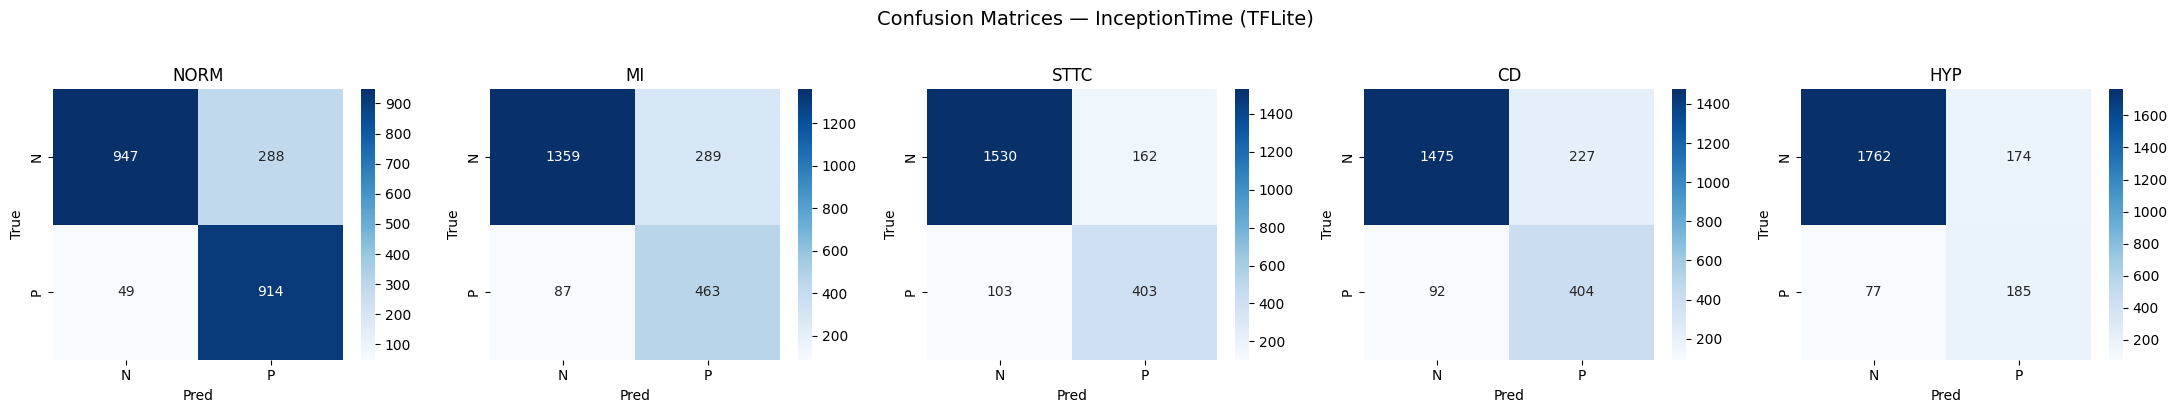

              precision    recall  f1-score   support

        NORM       0.76      0.95      0.84       963
          MI       0.62      0.84      0.71       550
        STTC       0.71      0.80      0.75       506
          CD       0.64      0.81      0.72       496
         HYP       0.52      0.71      0.60       262

   micro avg       0.68      0.85      0.75      2777
   macro avg       0.65      0.82      0.72      2777
weighted avg       0.68      0.85      0.76      2777
 samples avg       0.73      0.84      0.76      2777



In [8]:
best_name = ranked[0][0]
best_preds_bin = results[best_name]['preds_bin']

print(f"Best model by Macro AUC: {best_name} ({results[best_name]['macro_auc']:.4f})\n")

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for i, (ax, sc) in enumerate(zip(axes, SUPERCLASSES)):
    cm = confusion_matrix(Y_test[:, i], best_preds_bin[:, i])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['N', 'P'], yticklabels=['N', 'P'])
    ax.set_title(sc); ax.set(xlabel='Pred', ylabel='True')
plt.suptitle(f'Confusion Matrices — {best_name} (TFLite)', y=1.02, fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(drive_path, 'models', 'best_confusion_matrices.png'), dpi=150, bbox_inches='tight')
plt.show()

# Classification report for best model
print(classification_report(Y_test, best_preds_bin, target_names=SUPERCLASSES, zero_division=0))

## 8. Summary

In [10]:
print('\n' + '=' * 60)
print('SUMMARY')
print('=' * 60)

# Best accuracy
best_acc = ranked[0]
print(f'\n  \U0001f3c6 Best accuracy:  {best_acc[0]}')
print(f'     Macro AUC = {best_acc[1]["macro_auc"]:.4f}, Macro F1 = {best_acc[1]["macro_f1"]:.4f}')

# Best for edge (smallest + fastest)
best_edge = min(results.items(), key=lambda x: x[1]['size_mb'])
print(f'\n  \u26a1 Best for edge:  {best_edge[0]}')
print(f'     Size = {best_edge[1]["size_mb"]:.2f} MB, Latency = {best_edge[1]["latency_ms"]:.2f} ms/sample')
print(f'     Macro AUC = {best_edge[1]["macro_auc"]:.4f}')

# Best trade-off (AUC / size)
best_tradeoff = max(results.items(), key=lambda x: x[1]['macro_auc'] / x[1]['size_mb'])
print(f'\n  \u2696\ufe0f  Best trade-off: {best_tradeoff[0]}')
print(f'     AUC/MB = {best_tradeoff[1]["macro_auc"] / best_tradeoff[1]["size_mb"]:.4f}')

print('\n' + '=' * 60)
print('\nRun the best model\'s .tflite on your target edge device to')
print('confirm real-world latency and accuracy before deployment.')


SUMMARY

  🏆 Best accuracy:  InceptionTime
     Macro AUC = 0.9210, Macro F1 = 0.7242

  ⚡ Best for edge:  Transformer
     Size = 1.54 MB, Latency = 0.89 ms/sample
     Macro AUC = 0.9018

  ⚖️  Best trade-off: Transformer
     AUC/MB = 0.5863


Run the best model's .tflite on your target edge device to
confirm real-world latency and accuracy before deployment.
